# 02. 검사 예산 곡선 — 전체의 몇 %를 검사하면 불량을 몇 개 찾는가
01의 OOF 점수로, 평가 그룹(fold)마다 위험 점수 상위 ceil(b·n)개를 검사한다고 가정한다(b = 1%~100%).
동점은 정답을 쓰지 않고 기대값으로 처리한다. 무작위 선택은 해석적 기대값이다.

모든 수치는 이미 공개된 Stellantis N.V. 데이터 안의 교차검증이며, 새 생산 기간의 성능을 보장하지 않는다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import br
from br import features as F, budget as B, plot as P
P.setup(); pd.set_option("display.width", 220)
df = F.load(); y = df.y.values; NPOS = int(y.sum())
oof = pd.read_pickle(br.RES / "polito_oof.pkl").sort_values(["label", "seed", "row"])
LABELS = list(dict.fromkeys(oof.label))

curves = []
for (lab, s), g in oof.groupby(["label", "seed"], sort=False):
    curves.append(B.curve(y, g.score.values, g.fold.values).assign(label=lab, seed=s))
for s in range(5):
    fold = oof[(oof.label == LABELS[0]) & (oof.seed == s)].fold.values
    curves.append(B.random_curve(y, fold).assign(label="무작위 선택(기대값)", seed=s))
cv = pd.concat(curves, ignore_index=True)
cv.to_csv(br.RES / "polito_budget_curves.csv", index=False, encoding="utf-8-sig")
agg = cv.groupby(["label", "budget"]).agg(inspected=("inspected", "mean"), caught=("caught", "mean"),
                                         c_lo=("caught", "min"), c_hi=("caught", "max"),
                                         missed=("missed", "mean"), recall=("recall", "mean"),
                                         precision=("precision", "mean")).reset_index()

## 1. 검사 비율별 포착 불량 수 (5개 시드 평균)

In [2]:
SHOW = [5, 10, 20, 30, 50, 70, 90]
ORDER = ["무작위 선택(기대값)"] + LABELS
t = agg[agg.budget.isin([b / 100 for b in SHOW])].pivot(index="label", columns="budget", values="caught").loc[ORDER]
t.columns = [f"{int(round(c*100))}%" for c in t.columns]
print(f"전체 1,976개, 불량 {NPOS}개 중 포착한 불량 수(시드 평균)")
t.round(1)

전체 1,976개, 불량 79개 중 포착한 불량 수(시드 평균)


,5%,10%,20%,30%,50%,70%,90%
label,,,,,,,
무작위 선택(기대값),4.1,8.0,15.9,23.8,39.6,55.4,71.2
AE·기본16 (정답 미사용),2.0,6.8,17.4,28.8,51.4,66.6,77.4
CatBoost·기본16,35.0,43.0,55.8,62.4,70.0,75.0,78.6
CatBoost·도메인90,39.2,48.4,60.4,66.6,70.8,73.6,78.6
ExtraTrees·도메인90,38.2,49.0,62.2,67.4,72.8,75.1,78.1
TabICLv2·기본16,38.9,48.8,66.4,71.2,74.0,76.6,79.0
TabICLv2·도메인90,43.6,53.8,66.4,70.8,73.2,76.8,78.8
로지스틱·기본16,18.2,36.6,48.4,57.8,69.0,76.2,79.0
로지스틱·도메인90,27.0,45.6,63.0,69.6,75.4,78.0,79.0


## 2. 목표 포착률을 맞추려면 몇 %를 검사해야 하는가
시드마다 목표를 처음 만족하는 검사 비율을 구하고, 평균·최소~최대를 적는다.

In [3]:
TGT = [0.5, 0.8, 0.9, 0.95, 1.0]
rows = []
for lab in ORDER:
    per = [B.budget_for_recall(g, TGT) for _, g in cv[cv.label == lab].groupby("seed")]
    r = {"모델": lab}
    for t_ in TGT:
        v = np.array([p[t_][0] for p in per]) * 100
        r[f"{int(t_*100)}% 포착"] = f"{v.mean():.0f}% ({v.min():.0f}~{v.max():.0f})"
    rows.append(r)
need = pd.DataFrame(rows).set_index("모델")
need.to_csv(br.RES / "polito_budget_needed.csv", encoding="utf-8-sig")
need

,50% 포착,80% 포착,90% 포착,95% 포착,100% 포착
모델,,,,,
무작위 선택(기대값),50% (50~50),80% (80~80),90% (90~90),95% (95~95),100% (100~100)
AE·기본16 (정답 미사용),39% (38~44),67% (61~70),77% (73~81),84% (82~86),96% (93~100)
CatBoost·기본16,8% (7~10),34% (29~42),55% (45~66),73% (67~78),88% (82~93)
CatBoost·도메인90,5% (5~6),25% (22~32),59% (55~63),77% (75~79),88% (83~97)
ExtraTrees·도메인90,6% (5~7),21% (19~25),42% (39~45),70% (59~76),97% (86~100)
TabICLv2·기본16,6% (5~8),18% (17~20),33% (25~45),62% (55~71),84% (77~89)
TabICLv2·도메인90,5% (4~5),18% (16~20),36% (35~40),66% (62~69),82% (71~95)
로지스틱·기본16,12% (11~14),39% (37~41),56% (54~62),67% (63~72),79% (77~81)
로지스틱·도메인90,8% (8~8),22% (20~27),40% (33~44),55% (50~62),84% (82~89)


## 3. 그림 — 포착률 곡선과 남은 불량 수
주요 모델만 그린다(나머지는 표에 있음). 음영 = 5개 시드의 최소~최대.

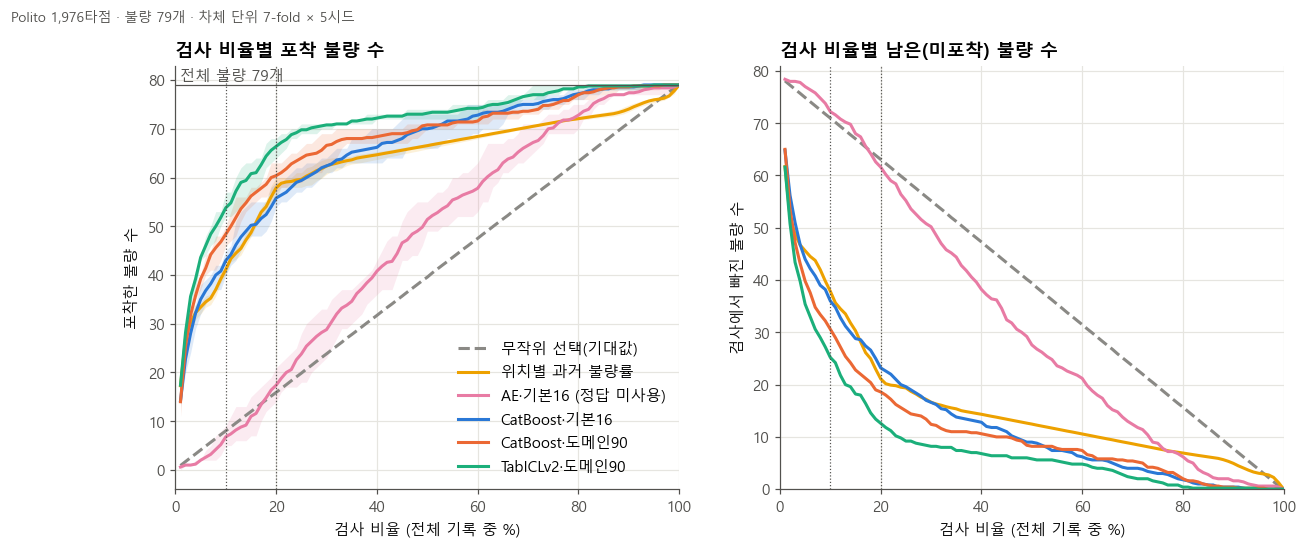

In [4]:
KEY = [("무작위 선택(기대값)", P.GRAY), ("위치별 과거 불량률", P.PAL[3]), ("AE·기본16 (정답 미사용)", P.PAL[4]),
       ("CatBoost·기본16", P.PAL[0]), ("CatBoost·도메인90", P.PAL[1]), ("TabICLv2·도메인90", P.PAL[2])]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for lab, col in KEY:
    a = agg[agg.label == lab]; x = a.budget * 100
    ls = "--" if lab.startswith("무작위") else "-"
    axes[0].plot(x, a.caught, ls, color=col, label=lab)
    axes[0].fill_between(x, a.c_lo, a.c_hi, color=col, alpha=.15, lw=0)
    axes[1].plot(x, a.missed, ls, color=col, label=lab)
for ax in axes:
    for b in (10, 20):
        ax.axvline(b, color=P.INK2, lw=.8, ls=":")
    ax.set_xlabel("검사 비율 (전체 기록 중 %)"); ax.set_xlim(0, 100)
axes[0].axhline(NPOS, color=P.INK2, lw=.8); axes[0].text(1, NPOS + 1, f"전체 불량 {NPOS}개", color=P.INK2)
axes[0].set_ylabel("포착한 불량 수"); axes[0].set_title("검사 비율별 포착 불량 수", loc="left", fontweight="bold")
axes[1].set_ylabel("검사에서 빠진 불량 수"); axes[1].set_title("검사 비율별 남은(미포착) 불량 수", loc="left", fontweight="bold")
axes[1].set_ylim(0, NPOS + 2)
axes[0].legend(loc="lower right")
fig.suptitle("Stellantis N.V. 1,976타점 · 불량 79개 · 차체 단위 7-fold × 5시드", x=0.01, ha="left", color=P.INK2, fontsize=9)
P.save(fig, "01_budget_curve"); plt.show()

## 4. 그림 — 0~30% 구간 확대와 정밀도
현장 검사 여력은 보통 낮은 비율이라 앞 구간을 따로 본다. 정밀도 = 검사한 기록 중 실제 불량 비율.

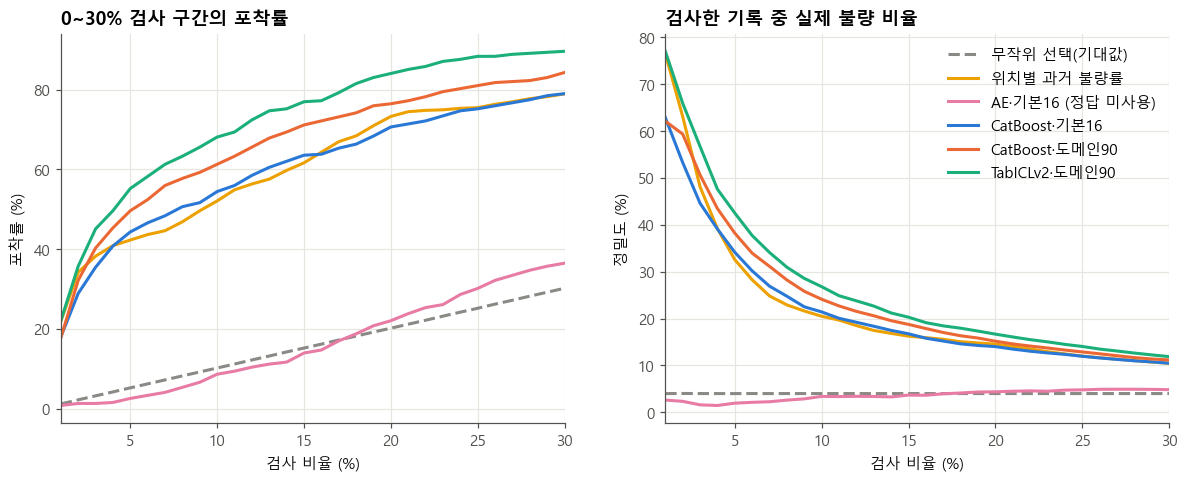

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for lab, col in KEY:
    a = agg[(agg.label == lab) & (agg.budget <= .30)]; x = a.budget * 100
    ls = "--" if lab.startswith("무작위") else "-"
    axes[0].plot(x, a.recall * 100, ls, color=col, label=lab)
    axes[1].plot(x, a.precision * 100, ls, color=col, label=lab)
axes[0].set_ylabel("포착률 (%)"); axes[0].set_title("0~30% 검사 구간의 포착률", loc="left", fontweight="bold")
axes[1].set_ylabel("정밀도 (%)"); axes[1].set_title("검사한 기록 중 실제 불량 비율", loc="left", fontweight="bold")
for ax in axes:
    ax.set_xlabel("검사 비율 (%)"); ax.set_xlim(1, 30)
axes[1].legend(loc="upper right")
P.save(fig, "02_budget_zoom"); plt.show()

## 5. 그림 — 목표 포착률별 필요 검사 비율

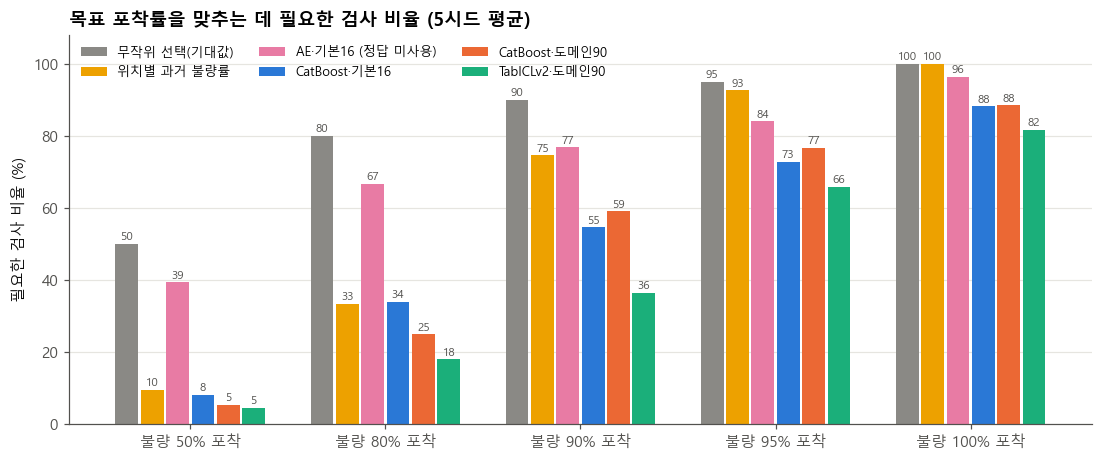

In [6]:
models = [k for k, _ in KEY]
cols = dict(KEY)
fig, ax = plt.subplots(figsize=(12, 4.6))
w = 0.13
for i, lab in enumerate(models):
    per = [B.budget_for_recall(g, TGT) for _, g in cv[cv.label == lab].groupby("seed")]
    m = [np.mean([p[t_][0] for p in per]) * 100 for t_ in TGT]
    xs = np.arange(len(TGT)) + (i - (len(models) - 1) / 2) * w
    ax.bar(xs, m, w * 0.9, color=cols[lab], label=lab)
    for xx, mm in zip(xs, m):
        ax.text(xx, mm + 1, f"{mm:.0f}", ha="center", fontsize=7.5, color=P.INK2)
ax.set_xticks(range(len(TGT))); ax.set_xticklabels([f"불량 {int(t_*100)}% 포착" for t_ in TGT])
ax.set_ylabel("필요한 검사 비율 (%)"); ax.set_ylim(0, 108); ax.grid(axis="x", visible=False)
ax.set_title("목표 포착률을 맞추는 데 필요한 검사 비율 (5시드 평균)", loc="left", fontweight="bold")
ax.legend(ncol=3, loc="upper left", fontsize=8.5)
P.save(fig, "03_budget_needed"); plt.show()

## 6. 대표 모델의 검사 비율표
도메인 CatBoost(1차 탐색 기준 모델)와 01번에서 가장 좋았던 도메인 TabICLv2, 시드 0.

In [8]:
for lab in ["CatBoost·도메인90", "TabICLv2·도메인90"]:
    g = cv[(cv.label == lab) & (cv.seed == 0) & cv.budget.isin([b / 100 for b in range(10, 101, 10)])].copy()
    g["검사 비율"] = (g.budget * 100).round().astype(int).astype(str) + "%"
    print(f"\n[{lab} · 시드 0]")
    display(g[["검사 비율", "inspected", "caught", "missed", "recall", "precision"]]
            .rename(columns={"inspected": "검사 수", "caught": "포착", "missed": "미포착", "recall": "포착률", "precision": "정밀도"})
            .round(3).set_index("검사 비율"))


[CatBoost·도메인90 · 시드 0]


,검사 수,포착,미포착,포착률,정밀도
검사 비율,,,,,
10%,200,50.0,29.0,0.633,0.250
20%,397,63.0,16.0,0.797,0.159
30%,595,69.0,10.0,0.873,0.116
40%,793,70.0,9.0,0.886,0.088
50%,990,71.0,8.0,0.899,0.072
60%,1187,72.0,7.0,0.911,0.061
70%,1387,74.0,5.0,0.937,0.053
80%,1583,77.0,2.0,0.975,0.049
90%,1782,79.0,0.0,1.000,0.044



[TabICLv2·도메인90 · 시드 0]


,검사 수,포착,미포착,포착률,정밀도
검사 비율,,,,,
10%,200,52.0,27.0,0.658,0.260
20%,397,66.0,13.0,0.835,0.166
30%,595,71.0,8.0,0.899,0.119
40%,793,72.0,7.0,0.911,0.091
50%,990,74.0,5.0,0.937,0.075
60%,1187,75.0,4.0,0.949,0.063
70%,1387,76.0,3.0,0.962,0.055
80%,1583,78.0,1.0,0.987,0.049
90%,1782,79.0,0.0,1.000,0.044
